## Load data
The images are in `../data/train` and `../data/test`, one folder per emotion. I load them as 48×48 grayscale and turn them into numpy arrays.
Train: 28,709 images, test: 7,178 images.

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split

DATA_DIR = "../data"
IMG = 48
CLASSES = ["angry", "disgust", "fear", "happy", "neutral", "sad", "surprise"]

train_ds = tf.keras.utils.image_dataset_from_directory(
    f"{DATA_DIR}/train", labels="inferred", label_mode="int",
    class_names=CLASSES, color_mode="grayscale",
    image_size=(IMG, IMG), batch_size=256, shuffle=False)
X_train_full = np.concatenate([x.numpy() for x, _ in train_ds]).astype("float32")
y_train_full = np.concatenate([y.numpy() for _, y in train_ds])

test_ds = tf.keras.utils.image_dataset_from_directory(
    f"{DATA_DIR}/test", labels="inferred", label_mode="int",
    class_names=CLASSES, color_mode="grayscale",
    image_size=(IMG, IMG), batch_size=256, shuffle=False)
X_test = np.concatenate([x.numpy() for x, _ in test_ds]).astype("float32")
y_test = np.concatenate([y.numpy() for _, y in test_ds])

print(X_train_full.shape, X_test.shape)

Found 28709 files belonging to 7 classes.
Found 7178 files belonging to 7 classes.
(28709, 48, 48, 1) (7178, 48, 48, 1)


## Explore the data
Number of images per emotion, then a look at some samples.

In [20]:
counts = pd.Series(y_train_full).value_counts().sort_index()
counts.index = CLASSES
print(counts)


angry       3995
disgust      436
fear        4097
happy       7215
neutral     4965
sad         4830
surprise    3171
Name: count, dtype: int64


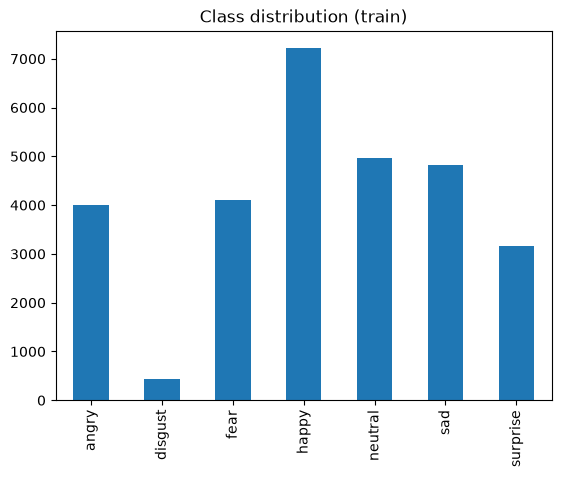

image shape: (48, 48, 1) | pixel range: 0.0 - 255.0


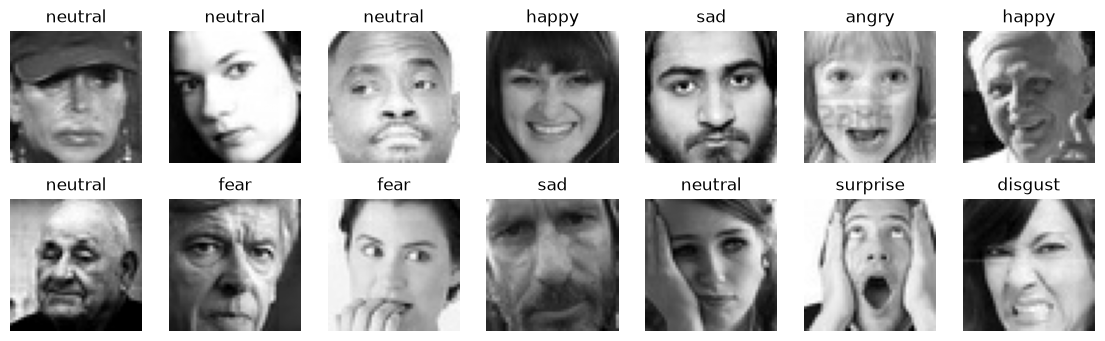

In [21]:
counts.plot(kind="bar", title="Class distribution (train)"); plt.show()

print("image shape:", X_train_full.shape[1:], "| pixel range:", X_train_full.min(), "-", X_train_full.max())

fig, axes = plt.subplots(2, 7, figsize=(14, 4))
for ax, i in zip(axes.ravel(), np.random.RandomState(0).choice(len(X_train_full), 14, replace=False)):
    ax.imshow(X_train_full[i].squeeze(), cmap="gray"); ax.set_title(CLASSES[y_train_full[i]]); ax.axis("off")
plt.show()

**What I see:**
- images are 48×48, pixel values 0–255
- the classes are not balanced: *happy* has the most images (7,215) and *disgust* has only 436
- because of this, accuracy alone can be misleading, so I also look at precision / recall per class and confusion matrix

## Preprocess
- scaling:  pixels divided by 255, so they are between 0 and 1
- 20% of the training set is kept for validation (`stratify`, so every class keeps the same share): 22,967 train / 5,742 validation
- the test set is only used at the end

In [22]:
X_train_full /= 255.0
X_test /= 255.0
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.2, stratify=y_train_full, random_state=42)
print(X_train.shape, X_val.shape, X_test.shape)

(22967, 48, 48, 1) (5742, 48, 48, 1) (7178, 48, 48, 1)


## Baseline model
A simple dense network: Flatten → Dense 512 → Dense 256 → Dense 7 (softmax).
- loss: sparse categorical crossentropy (labels are integers)
- 30 epochs, batch size 128

In [23]:
from tensorflow import keras
from tensorflow.keras.layers import Dense, Flatten

model = keras.Sequential([
    Flatten(),
    Dense(512, activation="relu"),
    Dense(256, activation="relu"),
    Dense(7, activation="softmax"),
])
model.compile(loss="sparse_categorical_crossentropy", metrics=["accuracy"])

hist = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                 epochs=30, batch_size=128)
model.summary()

Epoch 1/30
180/180 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.2292 - loss: 2.0301 - val_accuracy: 0.2679 - val_loss: 1.8026
Epoch 2/30
180/180 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.2770 - loss: 1.7718 - val_accuracy: 0.2736 - val_loss: 1.7576
Epoch 3/30
180/180 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.3050 - loss: 1.7327 - val_accuracy: 0.2936 - val_loss: 1.7252
Epoch 4/30
180/180 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.3191 - loss: 1.7111 - val_accuracy: 0.2732 - val_loss: 1.7791
Epoch 5/30
180/180 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.3310 - loss: 1.6871 - val_accuracy: 0.2783 - val_loss: 1.7616
Epoch 6/30
180/180 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.3441 - loss: 1.6743 - val_accuracy: 0.3110 - val_loss: 1.7757
Epoch 7/30
180/180 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.3517 - loss: 1.6524 - val_accuracy: 0.3598 - val_loss: 1.6417
Epoch 8/30
180/180 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.3566 - loss: 1.6353 - val_accu

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_7 (Flatten)             │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 512)            │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_27 (Dense)                │ (None, 7)              │         1,799 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,626,576 (10.02 MB)

 Trainable params: 1,313,287 (5.01 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,313,289 (5.01 MB)

## Training curves

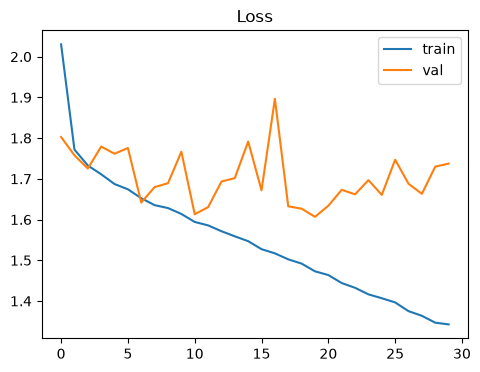

In [24]:
plt.figure(figsize=(5.5, 4))
plt.plot(hist.history["loss"], label="train")
plt.plot(hist.history["val_loss"], label="val")
plt.title("Loss")
plt.legend()
plt.show()

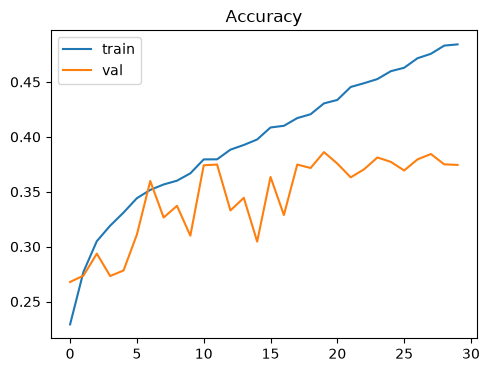

In [25]:
plt.figure(figsize=(5.5, 4))
plt.plot(hist.history["accuracy"], label="train")
plt.plot(hist.history["val_accuracy"], label="val")
plt.title("Accuracy")
plt.legend()
plt.show()

**What I see:** the training accuracy keeps going up (about 48% at the end) but the validation accuracy stays around 37–38% and the validation loss starts to go up. The model is **overfitting**: it learns the training images instead of general patterns.

##  Evaluation on the test set

225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
              precision    recall  f1-score   support

       angry       0.34      0.14      0.20       958
     disgust       0.80      0.04      0.07       111
        fear       0.30      0.15      0.20      1024
       happy       0.50      0.61      0.55      1774
     neutral       0.33      0.42      0.37      1233
         sad       0.35      0.26      0.30      1247
    surprise       0.37      0.69      0.48       831

    accuracy                           0.39      7178
   macro avg       0.43      0.33      0.31      7178
weighted avg       0.38      0.39      0.36      7178



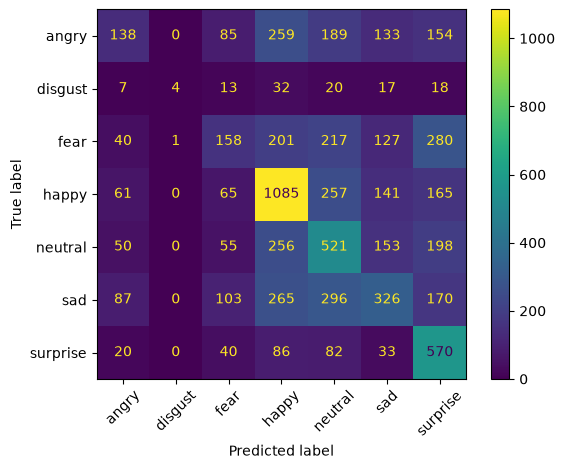

In [7]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

probs = model.predict(X_test)
y_pred = probs.argmax(1)
print(classification_report(y_test, y_pred, target_names=CLASSES))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=CLASSES).plot(xticks_rotation=45)
plt.show()


**Results (baseline):** accuracy 39%, macro F1 0.31.
- *happy* and *surprise* are found best (recall 0.61 and 0.69)
- *disgust* is almost never found (recall 0.04), *angry* and *fear* are weak (about 0.15)

## Error analysis
4,376 of the 7,178 test images are wrong (61%). Below are the 14 mistakes where the model was most confident.

4376 wrong out of 7178


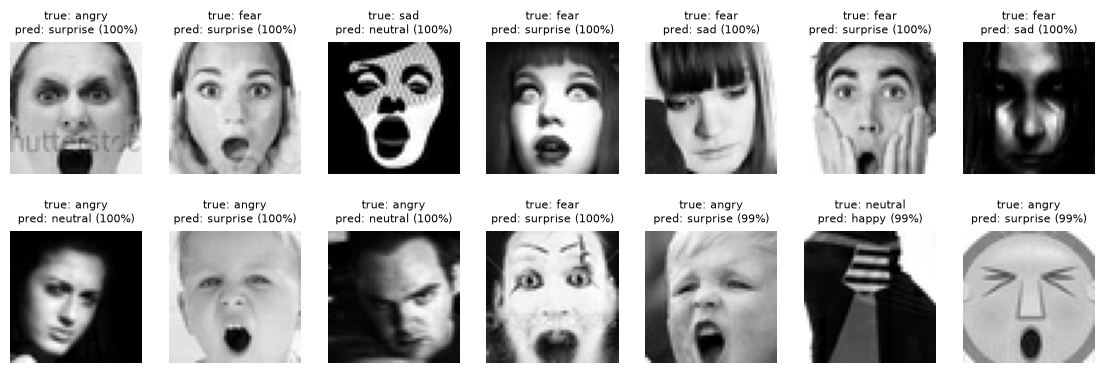

In [8]:
conf = probs.max(1)
wrong = np.where(y_pred != y_test)[0]
print(len(wrong), "wrong out of", len(y_test))

worst = wrong[np.argsort(-conf[wrong])][:14]          # the most confident mistakes
fig, axes = plt.subplots(2, 7, figsize=(14, 4.5))
for ax, i in zip(axes.ravel(), worst):
    ax.imshow(X_test[i].squeeze(), cmap="gray")
    ax.set_title(f"true: {CLASSES[y_test[i]]}\npred: {CLASSES[y_pred[i]]} ({conf[i]:.0%})", fontsize=8)
    ax.axis("off")
plt.show()

**Why it fails:**
- some faces are partly hidden or have bad lighting / blur
- some labels are ambiguous or even look wrong (FER2013 labels are noisy), for example fear vs surprise, or sad vs neutral
- rare classes like *disgust* have very few examples, so the model hardly learns them
- I also think some of those are plain out wrong, & look at the 2 in the right down corner... what is this?! 

## Trying to improve
I tried three things with a bigger dense network (1024 → 512 → 256), batch size 64 and early stopping (patience 15):
1. class weights (`balanced`), so rare classes count more
2. data augmentation (random flip, rotation, zoom, contrast), without class weights
3. class weights again, with Adam written explicitly. This one is the final `model2`.

In [11]:
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.utils.class_weight import compute_class_weight

weights = compute_class_weight("balanced", classes=np.unique(y_train), y=y_train)
class_weight = dict(enumerate(weights))

model2 = keras.Sequential([
    Flatten(),
    Dense(1024, activation="relu"),
    Dense(512, activation="relu"),
    Dense(256, activation="relu"),
    Dense(7, activation="softmax"),
])
model2.compile(loss="sparse_categorical_crossentropy", metrics=["accuracy"])

hist2 = model2.fit(X_train, y_train, validation_data=(X_val, y_val),
                   epochs=60, batch_size=64, class_weight=class_weight,
                   callbacks=[EarlyStopping(patience=15, restore_best_weights=True)])

Epoch 1/60
382/382 ━━━━━━━━━━━━━━━━━━━━ 11s 25ms/step - accuracy: 0.1549 - loss: 2.0271 - val_accuracy: 0.1857 - val_loss: 1.9301
Epoch 2/60
382/382 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - accuracy: 0.2291 - loss: 1.8962 - val_accuracy: 0.2621 - val_loss: 1.8328
Epoch 3/60
382/382 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - accuracy: 0.2349 - loss: 1.8689 - val_accuracy: 0.2872 - val_loss: 1.7721
Epoch 4/60
382/382 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - accuracy: 0.2515 - loss: 1.8460 - val_accuracy: 0.1869 - val_loss: 1.9436
Epoch 5/60
382/382 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - accuracy: 0.2597 - loss: 1.8304 - val_accuracy: 0.2802 - val_loss: 1.7892
Epoch 6/60
382/382 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - accuracy: 0.2565 - loss: 1.8159 - val_accuracy: 0.3197 - val_loss: 1.7559
Epoch 7/60
382/382 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - accuracy: 0.2733 - loss: 1.8051 - val_accuracy: 0.2326 - val_loss: 1.8743
Epoch 8/60
382/382 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - accuracy: 0.2737 - loss: 1.7918 - val_acc

In [14]:
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras import layers

model2 = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.2),
    Flatten(),
    Dense(1024, activation="relu"),
    Dense(512, activation="relu"),
    Dense(256, activation="relu"),
    Dense(7, activation="softmax"),
])
model2.compile(loss="sparse_categorical_crossentropy", metrics=["accuracy"])

hist2 = model2.fit(X_train, y_train, validation_data=(X_val, y_val),
                   epochs=60, batch_size=64,
                   callbacks=[EarlyStopping(patience=15, restore_best_weights=True)])

Epoch 1/60
382/382 ━━━━━━━━━━━━━━━━━━━━ 15s 34ms/step - accuracy: 0.2386 - loss: 1.9241 - val_accuracy: 0.2626 - val_loss: 1.7871
Epoch 2/60
382/382 ━━━━━━━━━━━━━━━━━━━━ 12s 32ms/step - accuracy: 0.2668 - loss: 1.7844 - val_accuracy: 0.1799 - val_loss: 1.9072
Epoch 3/60
382/382 ━━━━━━━━━━━━━━━━━━━━ 12s 32ms/step - accuracy: 0.2904 - loss: 1.7566 - val_accuracy: 0.3141 - val_loss: 1.7128
Epoch 4/60
382/382 ━━━━━━━━━━━━━━━━━━━━ 13s 33ms/step - accuracy: 0.2917 - loss: 1.7475 - val_accuracy: 0.3297 - val_loss: 1.6965
Epoch 5/60
382/382 ━━━━━━━━━━━━━━━━━━━━ 13s 33ms/step - accuracy: 0.2982 - loss: 1.7372 - val_accuracy: 0.3316 - val_loss: 1.6894
Epoch 6/60
382/382 ━━━━━━━━━━━━━━━━━━━━ 13s 33ms/step - accuracy: 0.3077 - loss: 1.7264 - val_accuracy: 0.3021 - val_loss: 1.7312
Epoch 7/60
382/382 ━━━━━━━━━━━━━━━━━━━━ 12s 32ms/step - accuracy: 0.3080 - loss: 1.7231 - val_accuracy: 0.2786 - val_loss: 1.7448
Epoch 8/60
382/382 ━━━━━━━━━━━━━━━━━━━━ 12s 32ms/step - accuracy: 0.3141 - loss: 1.7115 - 

In [15]:
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.utils.class_weight import compute_class_weight

weights = compute_class_weight("balanced", classes=np.unique(y_train), y=y_train)
class_weight = dict(enumerate(weights))

model2 = keras.Sequential([
    Flatten(),
    Dense(1024, activation="relu"),
    Dense(512, activation="relu"),
    Dense(256, activation="relu"),
    Dense(7, activation="softmax"),
])
model2.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

hist2 = model2.fit(X_train, y_train, validation_data=(X_val, y_val),
                   epochs=60, batch_size=64, class_weight=class_weight,
                   callbacks=[EarlyStopping(patience=15, restore_best_weights=True)])


Epoch 1/60
382/382 ━━━━━━━━━━━━━━━━━━━━ 14s 31ms/step - accuracy: 0.1743 - loss: 1.9692 - val_accuracy: 0.2765 - val_loss: 1.8413
Epoch 2/60
382/382 ━━━━━━━━━━━━━━━━━━━━ 11s 30ms/step - accuracy: 0.2566 - loss: 1.8696 - val_accuracy: 0.2679 - val_loss: 1.8725
Epoch 3/60
382/382 ━━━━━━━━━━━━━━━━━━━━ 12s 30ms/step - accuracy: 0.2750 - loss: 1.8347 - val_accuracy: 0.2698 - val_loss: 1.8251
Epoch 4/60
382/382 ━━━━━━━━━━━━━━━━━━━━ 11s 30ms/step - accuracy: 0.2761 - loss: 1.8050 - val_accuracy: 0.2661 - val_loss: 1.8027
Epoch 5/60
382/382 ━━━━━━━━━━━━━━━━━━━━ 11s 30ms/step - accuracy: 0.2863 - loss: 1.7748 - val_accuracy: 0.3153 - val_loss: 1.7522
Epoch 6/60
382/382 ━━━━━━━━━━━━━━━━━━━━ 11s 30ms/step - accuracy: 0.2884 - loss: 1.7651 - val_accuracy: 0.2422 - val_loss: 1.8731
Epoch 7/60
382/382 ━━━━━━━━━━━━━━━━━━━━ 11s 30ms/step - accuracy: 0.2868 - loss: 1.7602 - val_accuracy: 0.3211 - val_loss: 1.7339
Epoch 8/60
382/382 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step - accuracy: 0.2933 - loss: 1.7511 - 

225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
              precision    recall  f1-score   support

       angry       0.22      0.17      0.19       958
     disgust       0.13      0.43      0.20       111
        fear       0.23      0.15      0.18      1024
       happy       0.51      0.57      0.54      1774
     neutral       0.33      0.42      0.37      1233
         sad       0.33      0.23      0.27      1247
    surprise       0.45      0.53      0.49       831

    accuracy                           0.37      7178
   macro avg       0.31      0.36      0.32      7178
weighted avg       0.36      0.37      0.35      7178



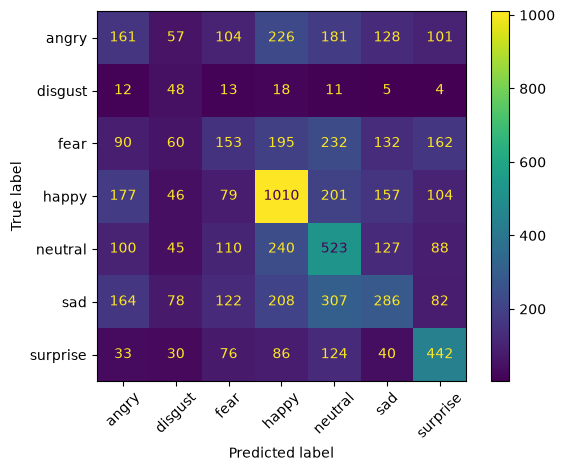

In [16]:
probs2 = model2.predict(X_test)
y_pred2 = probs2.argmax(1)
print(classification_report(y_test, y_pred2, target_names=CLASSES))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred2), display_labels=CLASSES).plot(xticks_rotation=45)
plt.show()

**Result of the final `model2`:** accuracy 37%, macro F1 0.32 (baseline: 39% and 0.31).
- class weights helped the rare classes a little (macro recall 0.36 vs 0.33) but lowered the overall accuracy
- augmentation did not help the dense network (validation accuracy stayed around 35% and jumped a lot between epochs)

**Conclusion:** none of the dense versions is clearly better than the baseline. A dense network flattens the image and loses the shape of the face, so it stops around 40%. A CNN would be the next step. (as I saw one of my classmates do it, but I'll wait for Mr.Ali to teach us about it first) 

of course, better data would be the best & biggest improvement

## Save the model for the app
`model2` is saved as `model2.keras`. The Streamlit app loads it, takes an uploaded face image and shows the predicted emotion.

In [17]:
model2.save("model2.keras")

## 10. Ethics and limitations
- **Low accuracy:** about 37–39%, so the model is wrong more than half of the time. It should not be used for real decisions.
- **Image quality:** it only sees a 48×48 grayscale image, so bad lighting, angles, glasses or a hand on the face, and low resolution hurt it.
- **Dataset bias:** the classes are unbalanced (*disgust* 436 images vs *happy* 7,215), so the model leans towards *happy* / *neutral* and almost never says *disgust*. FER2013 labels are also noisy.
- **Who is in the data:** we don't know the age, gender or skin-tone balance, so it can work worse for some groups.
- **Expression ≠ feeling:** a facial expression is not always the real emotion, and it differs between people and cultures.
- **Privacy and misuse:** faces are personal data and need consent. This should not be used for surveillance, hiring or grading people.
- **The app:** it resizes the whole uploaded image to 48×48, so photos should be a close-up of one face.